# Clasificar dígitos escritos a mano: MNIST de punta a punta

El reto del módulo parte con una carta escrita a mano que nadie logra leer. La idea para descifrarla es recortar cada carácter como una imagen y entrenar un clasificador que diga qué carácter es cada una. Antes de las letras, practicamos con dígitos: MNIST.

Este notebook junta todas las piezas del módulo en un solo entrenamiento:

- los datos con `transforms`, `Dataset` y `DataLoader` (`00-datos`);
- el modelo como clase de `nn.Module` (`01-modelos`);
- la entropía cruzada y `Adam` (`02-entrenamiento`);
- el dispositivo (`03-dispositivos`).

Después mira dónde se equivoca el modelo y lo pone a leer un mensaje escrito con dígitos.

Entrenar diez épocas con el pipeline completo tarda unos tres minutos en una CPU.

**Contenido**

1. Preparación
2. Los datos
3. Apartar una validación
4. El modelo
5. Dispositivo, pérdida y optimizador
6. Entrenar una época
7. Evaluar
8. Diez épocas
9. La prueba, una sola vez
10. Dónde se equivoca
11. Un mensaje secreto
12. Resumen y ejercicios

## 1. Preparación

In [1]:
import copy
import time

import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 2. Los datos

El pipeline de `00-datos`: `ToTensor` lleva cada imagen a un tensor `[1, 28, 28]` con valores entre 0 y 1, y `Normalize` la centra con la media y la desviación del conjunto de entrenamiento. La prueba usa exactamente la misma transformación.

In [2]:
transformacion = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

entrenamiento_completo = datasets.MNIST(root="../data", train=True, download=True, transform=transformacion)
prueba = datasets.MNIST(root="../data", train=False, download=True, transform=transformacion)
print("entrenamiento:", len(entrenamiento_completo), "  prueba:", len(prueba))

entrenamiento: 60000   prueba: 10000


## 3. Apartar una validación

En el curso, el modelo se evalúa en el conjunto de prueba después de cada época, para ver si sigue mejorando. Eso tiene un problema, el mismo que vimos en el proyecto de punta a punta del módulo 1: si la prueba se usa para decidir algo, como cuántas épocas entrenar, deja de medir el desempeño en datos que el modelo nunca influyó.

Por eso apartamos 5.000 imágenes del entrenamiento como **validación**. Se miran después de cada época y sirven para decidir. La prueba se usa una sola vez, al final. `random_split` separa un dataset al azar en partes del tamaño pedido, sin copiar los datos: cada parte es una lista de índices sobre el original.

In [3]:
entrenamiento, validacion = random_split(entrenamiento_completo, [55_000, 5_000],
                                         generator=torch.Generator().manual_seed(0))

cargador_entrenamiento = DataLoader(entrenamiento, batch_size=64, shuffle=True)
cargador_validacion = DataLoader(validacion, batch_size=1000)
cargador_prueba = DataLoader(prueba, batch_size=1000)

print(f"entrenamiento: {len(entrenamiento):6d} imágenes, {len(cargador_entrenamiento)} lotes de 64")
print(f"validación   : {len(validacion):6d} imágenes, {len(cargador_validacion)} lotes de 1000")
print(f"prueba       : {len(prueba):6d} imágenes, {len(cargador_prueba)} lotes de 1000")

entrenamiento:  55000 imágenes, 860 lotes de 64
validación   :   5000 imágenes, 5 lotes de 1000
prueba       :  10000 imágenes, 10 lotes de 1000


Solo el entrenamiento se mezcla. La validación y la prueba usan lotes grandes, porque al evaluar no se retiene memoria para `backward()` (`01-modelos/01_nn_module`, sección 9).

## 4. El modelo

Aplanar la imagen, una capa oculta de 128 neuronas con ReLU y una salida de 10 logits, uno por dígito:

In [4]:
class RedMNIST(nn.Module):
    def __init__(self):
        super().__init__()
        self.aplanar = nn.Flatten()
        self.capas = nn.Sequential(
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.capas(self.aplanar(x))      # [lote, 1, 28, 28] -> [lote, 784] -> [lote, 10]


x, y = next(iter(cargador_entrenamiento))
print("entrada:", tuple(x.shape), "  salida:", tuple(RedMNIST()(x).shape))
print("parámetros:", sum(p.numel() for p in RedMNIST().parameters()))

entrada: (64, 1, 28, 28)   salida: (64, 10)
parámetros: 101770


## 5. Dispositivo, pérdida y optimizador

El patrón de `03-dispositivos`: elegir el dispositivo, mover el modelo y después crear el optimizador. Entropía cruzada porque se predice una categoría, y `Adam` con su tasa habitual, 0.001.

In [5]:
if torch.cuda.is_available():
    dispositivo = torch.device("cuda")
elif torch.backends.mps.is_available():
    dispositivo = torch.device("mps")
else:
    dispositivo = torch.device("cpu")

torch.manual_seed(0)
modelo = RedMNIST().to(dispositivo)
criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
print("dispositivo:", dispositivo)

dispositivo: cpu


## 6. Entrenar una época

La función recorre el cargador una vez. En cada lote hace los pasos de siempre: mover al dispositivo, `zero_grad()`, predicción, pérdida, `backward()` y `step()`. Además lleva tres contadores para informar el progreso: la pérdida acumulada, los aciertos y las imágenes vistas.

Dos detalles:

- `perdida.item()` saca el número del tensor. Acumular `perdida` sin `.item()` guardaría el grafo de cada lote y la memoria crecería sin parar.
- `salida.argmax(dim=1)` es el dígito predicho: la posición del logit más alto. El curso usa `salida.max(dim=1)`, que devuelve el valor máximo y su posición; la posición es lo mismo que da `argmax`.

In [6]:
def entrenar_una_epoca(modelo, cargador, criterio, optimizador, dispositivo, informar_cada=None):
    modelo.train()
    perdida_total, correctas, vistas = 0.0, 0, 0
    tramo = [0.0, 0, 0]                                # lo mismo, pero desde el último informe

    for i, (x, y) in enumerate(cargador, start=1):
        x, y = x.to(dispositivo), y.to(dispositivo)

        optimizador.zero_grad()
        salida = modelo(x)
        perdida = criterio(salida, y)
        perdida.backward()
        optimizador.step()

        n = len(y)
        aciertos = (salida.argmax(dim=1) == y).sum().item()
        perdida_total += perdida.item() * n
        correctas += aciertos
        vistas += n
        tramo[0] += perdida.item() * n
        tramo[1] += aciertos
        tramo[2] += n

        if informar_cada and i % informar_cada == 0:
            print(f"   lote {i:3d}/{len(cargador)}   pérdida {tramo[0] / tramo[2]:.3f}   exactitud {tramo[1] / tramo[2]:.1%}")
            tramo = [0.0, 0, 0]

    return perdida_total / vistas, correctas / vistas

Entrenamos la primera época informando cada 100 lotes. Cada línea es el promedio de los 100 lotes anteriores:

In [7]:
inicio = time.perf_counter()
perdida_epoca, exactitud_epoca = entrenar_una_epoca(modelo, cargador_entrenamiento, criterio, optimizador,
                                                    dispositivo, informar_cada=100)
print(f"\népoca 1: pérdida {perdida_epoca:.3f}   exactitud {exactitud_epoca:.1%}   ({time.perf_counter() - inicio:.0f} s)")

   lote 100/860   pérdida 0.621   exactitud 82.1%


   lote 200/860   pérdida 0.314   exactitud 90.7%


   lote 300/860   pérdida 0.291   exactitud 91.4%


   lote 400/860   pérdida 0.231   exactitud 93.5%


   lote 500/860   pérdida 0.199   exactitud 93.8%


   lote 600/860   pérdida 0.172   exactitud 95.1%


   lote 700/860   pérdida 0.169   exactitud 94.8%


   lote 800/860   pérdida 0.153   exactitud 95.4%



época 1: pérdida 0.262   exactitud 92.3%   (19 s)


En los primeros 100 lotes el modelo ya pasa de adivinar (10%) a acertar más de 80% en promedio, y al final de la época los lotes se aciertan sobre el 95%. Cada informe mide lotes distintos, con pesos que fueron cambiando, así que es una estimación aproximada del progreso. La medida en serio es la de la sección siguiente.

## 7. Evaluar

La evaluación no tiene optimizador ni actualizaciones. Pone el modelo en modo evaluación, apaga autograd y cuenta aciertos sobre datos que el modelo no usó para entrenar:

In [8]:
def evaluar(modelo, cargador, criterio, dispositivo):
    modelo.eval()
    perdida_total, correctas = 0.0, 0
    with torch.no_grad():
        for x, y in cargador:
            x, y = x.to(dispositivo), y.to(dispositivo)
            salida = modelo(x)
            perdida_total += criterio(salida, y).item() * len(y)
            correctas += (salida.argmax(dim=1) == y).sum().item()
    n = len(cargador.dataset)
    return perdida_total / n, correctas / n


perdida_val, exactitud_val = evaluar(modelo, cargador_validacion, criterio, dispositivo)
print(f"después de 1 época, validación: pérdida {perdida_val:.3f}   exactitud {exactitud_val:.1%}")

después de 1 época, validación: pérdida 0.150   exactitud 95.4%


La exactitud es la fracción de aciertos: si acierta 4.800 de 5.000, es 96%. `evaluar` deja el modelo en modo evaluación, y por eso `entrenar_una_epoca` empieza con `modelo.train()`: sin esa línea, el modelo seguiría en el modo equivocado en las épocas siguientes. Con esta red no cambiaría nada, porque no tiene capas como `Dropout`, pero con otra sí.

## 8. Diez épocas

Seguimos hasta completar diez épocas, midiendo la validación al final de cada una. Como en el proyecto del módulo 1, guardamos una copia del estado del modelo en la época con mejor exactitud de validación.

In [9]:
historia = {"perdida": [perdida_epoca], "exactitud": [exactitud_epoca],
            "perdida_val": [perdida_val], "exactitud_val": [exactitud_val]}
mejor_exactitud, mejor_epoca, mejor_estado = exactitud_val, 1, copy.deepcopy(modelo.state_dict())

for epoca in range(2, 11):
    inicio = time.perf_counter()
    perdida_epoca, exactitud_epoca = entrenar_una_epoca(modelo, cargador_entrenamiento, criterio, optimizador, dispositivo)
    perdida_val, exactitud_val = evaluar(modelo, cargador_validacion, criterio, dispositivo)

    for clave, valor in zip(historia, [perdida_epoca, exactitud_epoca, perdida_val, exactitud_val]):
        historia[clave].append(valor)
    if exactitud_val > mejor_exactitud:
        mejor_exactitud, mejor_epoca, mejor_estado = exactitud_val, epoca, copy.deepcopy(modelo.state_dict())

    print(f"época {epoca:2d}   entrenamiento: pérdida {perdida_epoca:.3f}, exactitud {exactitud_epoca:.2%}   "
          f"validación: pérdida {perdida_val:.3f}, exactitud {exactitud_val:.2%}   ({time.perf_counter() - inicio:.0f} s)")

print(f"\nmejor época: {mejor_epoca}, con exactitud de validación {mejor_exactitud:.2%}")

época  2   entrenamiento: pérdida 0.113, exactitud 96.59%   validación: pérdida 0.112, exactitud 96.46%   (20 s)


época  3   entrenamiento: pérdida 0.079, exactitud 97.54%   validación: pérdida 0.098, exactitud 97.00%   (21 s)


época  4   entrenamiento: pérdida 0.061, exactitud 98.11%   validación: pérdida 0.100, exactitud 97.08%   (20 s)


época  5   entrenamiento: pérdida 0.048, exactitud 98.44%   validación: pérdida 0.108, exactitud 96.86%   (20 s)


época  6   entrenamiento: pérdida 0.040, exactitud 98.73%   validación: pérdida 0.087, exactitud 97.44%   (20 s)


época  7   entrenamiento: pérdida 0.031, exactitud 98.95%   validación: pérdida 0.095, exactitud 97.04%   (20 s)


época  8   entrenamiento: pérdida 0.025, exactitud 99.20%   validación: pérdida 0.096, exactitud 97.30%   (20 s)


época  9   entrenamiento: pérdida 0.023, exactitud 99.26%   validación: pérdida 0.098, exactitud 97.46%   (20 s)


época 10   entrenamiento: pérdida 0.020, exactitud 99.29%   validación: pérdida 0.095, exactitud 97.68%   (20 s)

mejor época: 10, con exactitud de validación 97.68%


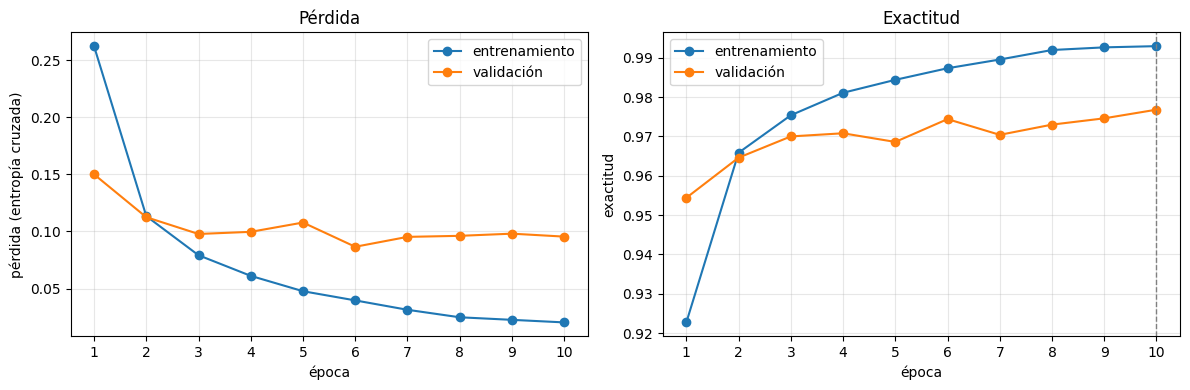

In [10]:
epocas = range(1, 11)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].plot(epocas, historia["perdida"], marker="o", label="entrenamiento")
ejes[0].plot(epocas, historia["perdida_val"], marker="o", label="validación")
ejes[0].set_ylabel("pérdida (entropía cruzada)")
ejes[0].set_title("Pérdida")

ejes[1].plot(epocas, historia["exactitud"], marker="o", label="entrenamiento")
ejes[1].plot(epocas, historia["exactitud_val"], marker="o", label="validación")
ejes[1].axvline(mejor_epoca, color="gray", linestyle="--", linewidth=1)
ejes[1].set_ylabel("exactitud")
ejes[1].set_title("Exactitud")

for eje in ejes:
    eje.set_xlabel("época")
    eje.set_xticks(list(epocas))
    eje.grid(alpha=0.3)
    eje.legend()
plt.tight_layout()
plt.show()

La pérdida de entrenamiento baja en todas las épocas, de 0.26 a 0.02. La de validación baja hasta la época 3 y desde ahí se mueve entre 0.09 y 0.11, sin una tendencia clara. La exactitud de validación sube rápido hasta 97% en la época 3 y después avanza a saltos chicos, hasta 97.7% en la época 10, la mejor. La de entrenamiento, mientras tanto, sigue hasta 99.3%.

Esa distancia entre las dos curvas, que se abre desde la época 3, es el comienzo del **sobreajuste**: el modelo sigue mejorando en las imágenes que ve una y otra vez, y casi nada en las nuevas. Con diez épocas basta. Más épocas darían a lo sumo décimas en la validación, mientras la distancia con el entrenamiento sigue creciendo.

En la época 1 la validación sale *mejor* que el entrenamiento, y no es un error. La cifra de entrenamiento es el promedio de toda la época, incluidos los primeros lotes, cuando el modelo todavía adivinaba. La de validación se mide al final, con el modelo ya entrenado durante toda la época.

## 9. La prueba, una sola vez

Cargamos el estado de la mejor época y lo evaluamos en las 10.000 imágenes de prueba:

In [11]:
modelo.load_state_dict(mejor_estado)
perdida_prueba, exactitud_prueba = evaluar(modelo, cargador_prueba, criterio, dispositivo)
print(f"prueba: pérdida {perdida_prueba:.3f}   exactitud {exactitud_prueba:.2%}   "
      f"({round((1 - exactitud_prueba) * len(prueba))} errores de {len(prueba)})")

prueba: pérdida 0.089   exactitud 97.72%   (228 errores de 10000)


97.7% en la prueba, casi igual que en la validación. La validación fue una buena estimación de lo que el modelo hace con imágenes nuevas, y la prueba lo confirma sin haber influido en ninguna decisión.

## 10. Dónde se equivoca

Una sola cifra no dice dónde falla el modelo. Guardamos las probabilidades que le da a cada dígito en cada imagen de prueba:

In [12]:
def predecir(modelo, cargador, dispositivo):
    modelo.eval()
    probabilidades, etiquetas = [], []
    with torch.no_grad():
        for x, y in cargador:
            probabilidades.append(modelo(x.to(dispositivo)).softmax(dim=1).cpu())
            etiquetas.append(y)
    return torch.cat(probabilidades), torch.cat(etiquetas)


probabilidades, etiquetas = predecir(modelo, cargador_prueba, dispositivo)
confianza, predicciones = probabilidades.max(dim=1)
errores = predicciones != etiquetas

print("exactitud por dígito:")
for d in range(10):
    de_d = etiquetas == d
    print(f"   {d}: {(~errores[de_d]).float().mean():.1%}   ({errores[de_d].sum().item()} errores de {de_d.sum().item()})")

exactitud por dígito:
   0: 98.8%   (12 errores de 980)
   1: 99.1%   (10 errores de 1135)
   2: 95.3%   (48 errores de 1032)
   3: 97.8%   (22 errores de 1010)
   4: 98.3%   (17 errores de 982)
   5: 98.0%   (18 errores de 892)
   6: 97.3%   (26 errores de 958)
   7: 98.7%   (13 errores de 1028)
   8: 97.1%   (28 errores de 974)
   9: 96.6%   (34 errores de 1009)


El 1 y el 0 son los más fáciles: casi no tienen variantes. El 2 es el más difícil, con 48 errores, más del doble que la mayoría, seguido del 9 y el 8.

La **matriz de confusión** cuenta, para cada dígito real, qué predijo el modelo. La diagonal son los aciertos; la dejamos en blanco para que se vean los errores:

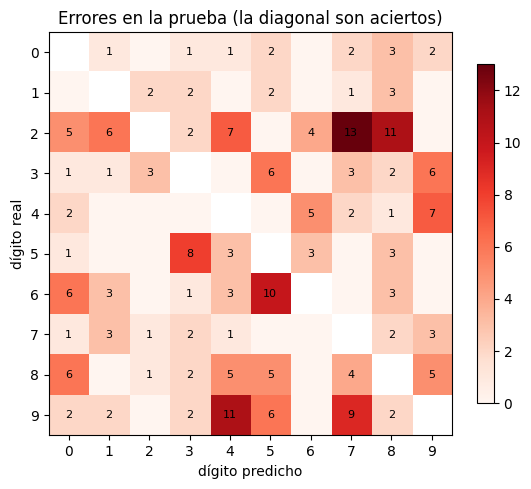

confusiones más frecuentes:
   un 2 leído como 7: 13 veces
   un 9 leído como 4: 11 veces
   un 2 leído como 8: 11 veces
   un 6 leído como 5: 10 veces
   un 9 leído como 7: 9 veces


In [13]:
confusion = torch.bincount(etiquetas * 10 + predicciones, minlength=100).reshape(10, 10)
solo_errores = confusion.clone().float()
solo_errores.fill_diagonal_(float("nan"))

fig, eje = plt.subplots(figsize=(6.5, 5.5))
imagen = eje.imshow(solo_errores, cmap="Reds")
for real in range(10):
    for predicho in range(10):
        if real != predicho and confusion[real, predicho] > 0:
            eje.text(predicho, real, confusion[real, predicho].item(), ha="center", va="center", fontsize=8)
eje.set_xticks(range(10))
eje.set_yticks(range(10))
eje.set_xlabel("dígito predicho")
eje.set_ylabel("dígito real")
eje.set_title("Errores en la prueba (la diagonal son aciertos)")
plt.colorbar(imagen, ax=eje, shrink=0.8)
plt.show()

pares = [(confusion[r, p].item(), r, p) for r in range(10) for p in range(10) if r != p]
print("confusiones más frecuentes:")
for cantidad, real, predicho in sorted(pares, reverse=True)[:5]:
    print(f"   un {real} leído como {predicho}: {cantidad} veces")

Las confusiones tienen sentido mirando los trazos. Un 2 escrito con la base corta y el trazo superior recto se parece a un 7. Un 9 con la parte de arriba abierta es casi un 4, y el 9 y el 7 comparten la diagonal larga. Un 6 con el círculo pequeño y la parte de arriba curva se parece a un 5. La fila del 2 es la más cargada: se confunde con casi todos los dígitos.

Los errores más instructivos son los que el modelo comete **con mucha confianza**. Las 12 imágenes donde se equivocó dándole más probabilidad a la respuesta incorrecta:

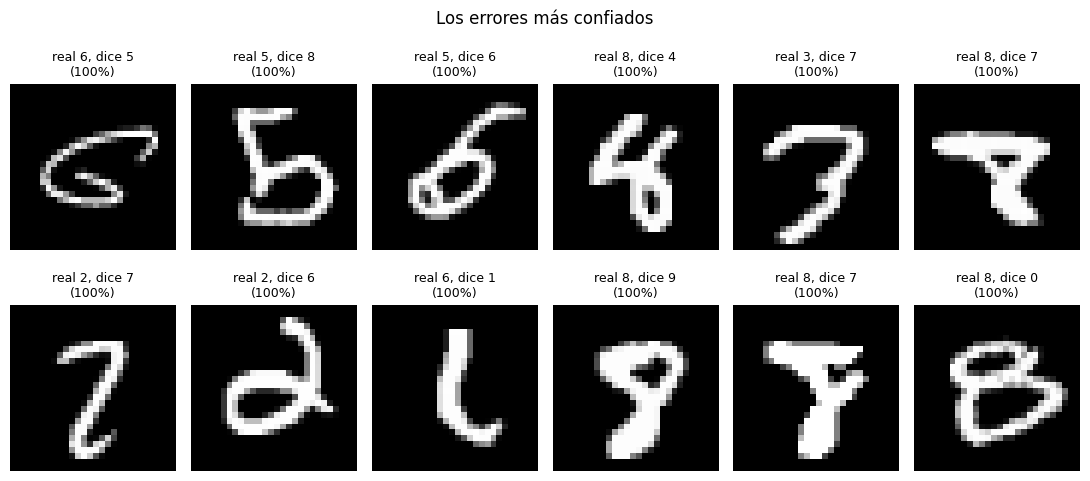

In [14]:
indices = torch.nonzero(errores).squeeze(1)
peores = indices[confianza[indices].argsort(descending=True)[:12]]

fig, ejes = plt.subplots(2, 6, figsize=(11, 5.2))
for eje, i in zip(ejes.flat, peores.tolist()):
    eje.imshow(prueba.data[i], cmap="gray")
    eje.set_title(f"real {etiquetas[i].item()}, dice {predicciones[i].item()}\n({confianza[i]:.0%})", fontsize=9)
    eje.axis("off")
plt.suptitle("Los errores más confiados")
plt.tight_layout()
plt.show()

El modelo se equivocó en todas estas con una confianza de prácticamente 100%. Varias son difíciles también para una persona: un 6 con el círculo abierto que parece una G, un 5 con la panza cerrada como un 8, un 3 que se lee como 7. Alguna parece directamente mal etiquetada, porque MNIST tiene unas pocas etiquetas dudosas. Los errores confiados son los que más preocupan en un sistema real, porque no dan ninguna señal de alerta.

La confianza sirve igual como señal. Agrupamos las predicciones según la probabilidad que el modelo le dio a su respuesta y medimos la exactitud de cada grupo:

In [15]:
tramos = [(0.0, 0.5), (0.5, 0.9), (0.9, 0.99), (0.99, 1.01)]
for bajo, alto in tramos:
    en_tramo = (confianza >= bajo) & (confianza < alto)
    print(f"confianza entre {bajo:.0%} y {min(alto, 1):.0%}: {en_tramo.sum().item():5d} imágenes   "
          f"exactitud {(~errores[en_tramo]).float().mean():.1%}")

dudosas = confianza < 0.9
print(f"\ncon menos de 90% de confianza: {dudosas.sum().item()} imágenes ({dudosas.float().mean():.1%} de la prueba), "
      f"con {errores[dudosas].sum().item()} de los {errores.sum().item()} errores ({errores[dudosas].sum() / errores.sum():.0%})")

confianza entre 0% y 50%:    20 imágenes   exactitud 50.0%
confianza entre 50% y 90%:   336 imágenes   exactitud 61.3%
confianza entre 90% y 99%:   475 imágenes   exactitud 89.1%
confianza entre 99% y 100%:  9169 imágenes   exactitud 99.6%

con menos de 90% de confianza: 356 imágenes (3.6% de la prueba), con 140 de los 228 errores (61%)


El 92% de las imágenes se predice con más de 99% de confianza, y ahí el modelo acierta el 99.6%. Cuando duda, falla mucho más: con menos de 90% de confianza acierta apenas la mitad o un poco más. Esas imágenes dudosas son el 3.6% de la prueba y concentran el 61% de los errores. Un sistema real podría mandarlas a revisión humana: revisando una de cada 28 imágenes, se evitan seis de cada diez errores.

## 11. Un mensaje secreto

Escribimos un mensaje con imágenes de la prueba: los primeros diez dígitos de π, **3141592653**. Lo escribimos dos veces:

- **con letra clara**: para cada dígito, una imagen de ese dígito elegida al azar;
- **con mala letra**: para cada dígito, una de las imágenes a las que el modelo le dio menos probabilidad a su clase real, las más difíciles de la prueba.

El modelo lee cada mensaje y marca con `?` los dígitos que leyó con menos de 90% de confianza.

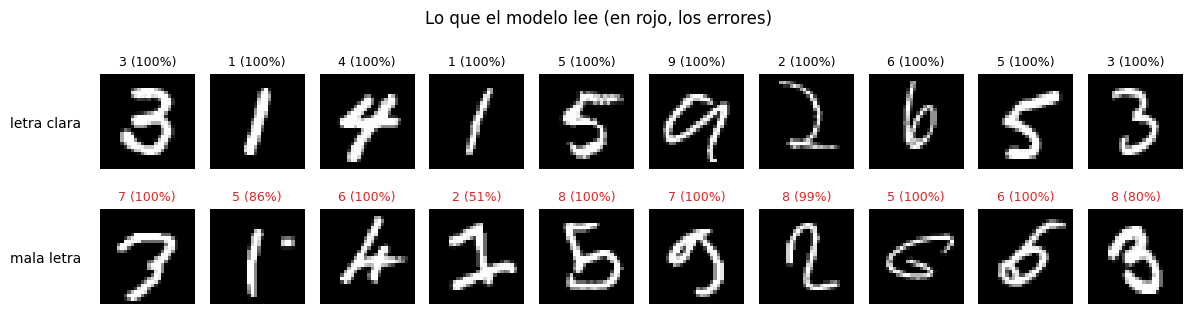

mensaje original : 3141592653
con letra clara  : 3141592653   marcado: 3141592653
con mala letra   : 7562878568   marcado: 7?6?87856?


In [16]:
mensaje = "3141592653"
generador = torch.Generator().manual_seed(3)

clara, dificil = [], []
for d in map(int, mensaje):
    de_d = torch.nonzero(etiquetas == d).squeeze(1)
    clara.append(de_d[torch.randint(len(de_d), (1,), generator=generador)].item())
    for i in de_d[probabilidades[de_d, d].argsort()].tolist():     # de la más difícil a la más fácil
        if i not in dificil:
            dificil.append(i)
            break


def leer(indices):
    lectura = ""
    for i in indices:
        lectura += str(predicciones[i].item()) if confianza[i] >= 0.9 else "?"
    return lectura


fig, ejes = plt.subplots(2, len(mensaje), figsize=(12, 3.4))
for fila, (nombre, indices) in enumerate([("letra clara", clara), ("mala letra", dificil)]):
    for eje, i in zip(ejes[fila], indices):
        eje.imshow(prueba.data[i], cmap="gray")
        eje.set_title(f"{predicciones[i].item()} ({confianza[i]:.0%})", fontsize=9,
                      color="black" if predicciones[i] == etiquetas[i] else "tab:red")
        eje.axis("off")
    ejes[fila][0].text(-6, 14, nombre, ha="right", va="center", fontsize=10)
plt.suptitle("Lo que el modelo lee (en rojo, los errores)")
plt.tight_layout()
plt.show()

print("mensaje original :", mensaje)
print("con letra clara  :", "".join(str(predicciones[i].item()) for i in clara), "  marcado:", leer(clara))
print("con mala letra   :", "".join(str(predicciones[i].item()) for i in dificil), "  marcado:", leer(dificil))

Con letra clara, el modelo lee el mensaje completo, y con 100% de confianza en cada dígito. Con mala letra lee **7562878568**: no acierta ni un dígito. Y la marca de duda solo atrapa 3 de los 10 errores; los otros 7 los lee con más de 90% de confianza.

La "mala letra" es injusta a propósito: son las imágenes más difíciles de las 10.000, elegidas justamente porque el modelo les da poca probabilidad a su clase real, así que no representan lo que pasa en promedio (97.7% de aciertos). Pero muestra el problema con que parte el reto del curso. Un clasificador que funciona bien con caracteres parecidos a los de su entrenamiento puede devolver, frente a una letra manuscrita distinta, un mensaje sin sentido, y hacerlo sin dudar.

## 12. Resumen

- El flujo completo: `transforms` y `DataLoader` para los datos, una clase de `nn.Module` para el modelo, entropía cruzada y `Adam`, y el patrón de dispositivos.
- `entrenar_una_epoca` empieza con `modelo.train()` y repite en cada lote: mover al dispositivo, `zero_grad()`, predicción, pérdida, `backward()`, `step()`. Las métricas se acumulan con `.item()`.
- `evaluar` usa `modelo.eval()` y `torch.no_grad()`, no tiene optimizador y cuenta aciertos con `argmax`.
- Se aparta una **validación** para mirar después de cada época y elegir la mejor; la **prueba** se usa una vez, al final.
- Cuando la exactitud de validación deja de mejorar, más épocas no ayudan, y la distancia con la de entrenamiento es el comienzo del sobreajuste.
- Para entender un modelo hay que mirar sus errores: por dígito, con la matriz de confusión y empezando por los más confiados.
- La confianza del modelo es una señal útil: sus predicciones dudosas fallan mucho más que las seguras.

## Ejercicios

1. Entrena con `SGD` y `lr=0.1` en vez de `Adam`. ¿Cómo cambian las curvas de la sección 8?
2. Cambia la capa oculta a 256 y a 512 neuronas. ¿Cuántos parámetros tiene cada versión? ¿Mejora la validación?
3. Agrega `nn.Dropout(0.2)` después de la ReLU y entrena de nuevo. ¿Qué pasa con la distancia entre las curvas de entrenamiento y validación? Después borra el `modelo.eval()` de `evaluar` y mira qué cambia.
4. Usa la validación para elegir el número de épocas, y después entrena un modelo nuevo con las 60.000 imágenes durante esa cantidad de épocas. Evalúalo en la prueba. ¿Mejora?
5. Dibuja un dígito propio de 28 × 28 (en un editor de imágenes o con matplotlib) y clasifícalo. ¿Qué preparación necesita para parecerse a MNIST? (Fíjate en el color del fondo, el grosor del trazo y el centrado.)
6. Elige la confusión más frecuente de la sección 10 y mira diez ejemplos. ¿Hay algo en la forma de esos dígitos que explique el error?